In [1]:
# SEL 1: Import
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

sns.set_theme(style="whitegrid")

In [2]:
# SEL 2: Muat data
df = pd.read_csv("../data/tips.csv")

print("--- 5 Baris Pertama ---")
print(df.head())
print("\n--- Nama Kolom ---")
print(df.columns)
print("\n--- Info ---")
df.info()

--- 5 Baris Pertama ---
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

--- Nama Kolom ---
Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [3]:
# SEL 3: Statistik dan kualitas data
print("--- Ringkasan Statistik ---")
print(df[["total_bill", "tip"]].describe().round(2))
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\nData duplikat:", df.duplicated().sum())

--- Ringkasan Statistik ---
       total_bill     tip
count      244.00  244.00
mean        19.79    3.00
std          8.90    1.38
min          3.07    1.00
25%         13.35    2.00
50%         17.80    2.90
75%         24.13    3.56
max         50.81   10.00

--- Missing Values ---
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Data duplikat: 1


In [4]:
# SEL 4: Cek outlier (metode IQR)
for kolom in ["total_bill", "tip"]:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    print(f"{kolom}: {jumlah} outlier (batas {batas_bawah:.2f} - {batas_atas:.2f})")

total_bill: 9 outlier (batas -2.82 - 40.30)
tip: 9 outlier (batas -0.34 - 5.91)


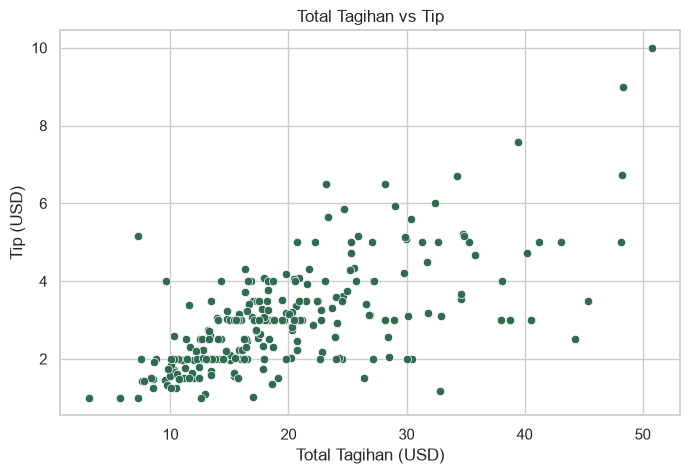

In [5]:
# SEL 5: Scatterplot (validasi tren linear, wajib di modul)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="total_bill", y="tip", color="#2f6b4f")
plt.title("Total Tagihan vs Tip")
plt.xlabel("Total Tagihan (USD)")
plt.ylabel("Tip (USD)")
plt.show()

In [6]:
# SEL 6: Korelasi
korelasi = df["total_bill"].corr(df["tip"])
print(f"Korelasi total_bill dan tip: {korelasi:.3f}")

Korelasi total_bill dan tip: 0.676


In [7]:
# SEL 7: Pisahkan X dan y, bagi data latih dan uji
X = df[["total_bill"]]
y = df["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

Data latih: 195 | Data uji: 49


In [8]:
# SEL 8: Latih model
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept   : {model.intercept_:.4f}")
print(f"Koefisien   : {model.coef_[0]:.4f}")

Intercept   : 0.9252
Koefisien   : 0.1070


In [9]:
# SEL 9: Prediksi dan evaluasi
predictions = model.predict(X_test)

mae = metrics.mean_absolute_error(y_test, predictions)
mse = metrics.mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Absolute Error (MAE): 0.6209
Mean Squared Error (MSE): 0.5688
Root Mean Squared Error (RMSE): 0.7542
R-squared (R2): 0.5449


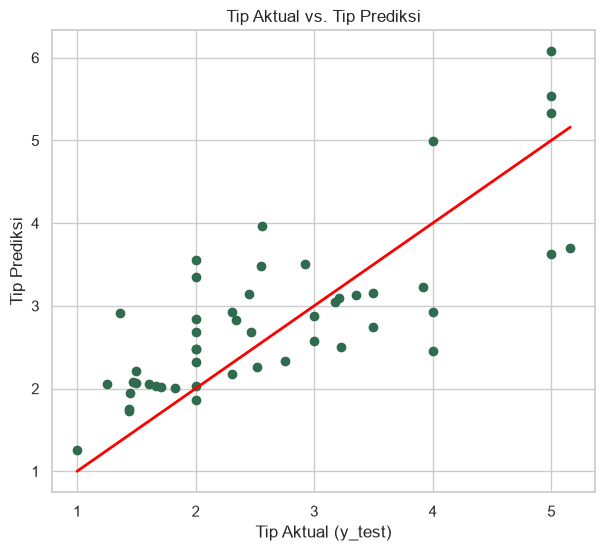

In [10]:
# SEL 10: Visual tip aktual vs prediksi
plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, color="#2f6b4f")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2)
plt.xlabel("Tip Aktual (y_test)")
plt.ylabel("Tip Prediksi")
plt.title("Tip Aktual vs. Tip Prediksi")
plt.show()

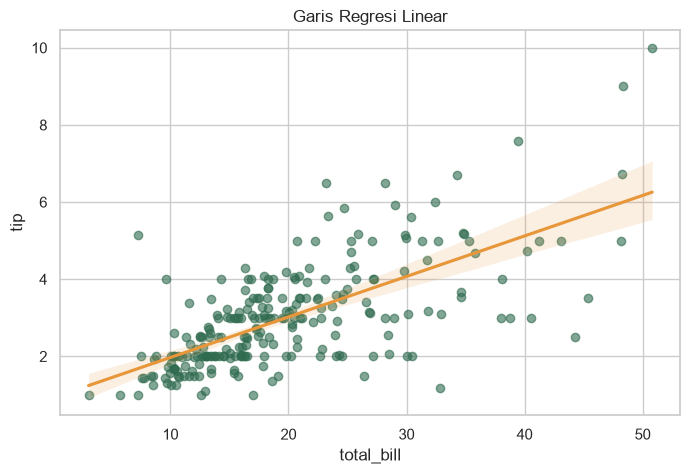

In [11]:
# SEL 11: Garis regresi pada seluruh data
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="total_bill", y="tip",
            scatter_kws={"color": "#2f6b4f", "alpha": 0.6},
            line_kws={"color": "#e8963a"})
plt.title("Garis Regresi Linear")
plt.show()

In [12]:
# SEL 12: Interpretasi intersep dan koefisien
print(f"Persamaan: tip = {model.intercept_:.4f} + {model.coef_[0]:.4f} x total_bill")
print(f"Setiap kenaikan 1 USD tagihan, tip naik sekitar {model.coef_[0]:.4f} USD")
print(f"R2 = {r2:.2%} variasi tip dijelaskan oleh total_bill")
print(f"RMSE = {rmse:.2f} USD (rata-rata prediksi meleset)")

Persamaan: tip = 0.9252 + 0.1070 x total_bill
Setiap kenaikan 1 USD tagihan, tip naik sekitar 0.1070 USD
R2 = 54.49% variasi tip dijelaskan oleh total_bill
RMSE = 0.75 USD (rata-rata prediksi meleset)


In [14]:
# SEL 13: Simpan model (Joblib) dan metrik (JSON)
joblib.dump(model, "../model/model_tip.joblib")

info_model = {
    "r2": round(float(r2), 4),
    "rmse": round(float(rmse), 4),
    "mae": round(float(mae), 4),
    "intercept": round(float(model.intercept_), 4),
    "coef": round(float(model.coef_[0]), 4),
    "n_total": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "x_min": float(df["total_bill"].min()),
    "x_max": float(df["total_bill"].max()),
}
with open("../model/metrics.json", "w", encoding="utf-8") as f:
    json.dump(info_model, f, indent=2)

print("Model dan metrik tersimpan.")

Model dan metrik tersimpan.


In [15]:
# SEL 14: Uji muat model
model_uji = joblib.load("../model/model_tip.joblib")
contoh = pd.DataFrame({"total_bill": [25.0]})
print(f"Prediksi tip untuk tagihan 25 USD: {model_uji.predict(contoh)[0]:.2f} USD")

Prediksi tip untuk tagihan 25 USD: 3.60 USD
